# Figura 6.1 - Sensibilidad al porcentaje top en CV ensemble

Genera una figura para mostrar cómo cambian los scores Public y Private de Kaggle al variar el porcentaje de eventos clasificados como `signal` usando los scores del CV ensemble.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

In [2]:
def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


project_root = find_project_root()
img_dir = project_root / "img"
img_dir.mkdir(parents=True, exist_ok=True)
output_path = img_dir / "fig_6_1_kaggle_porcentaje_cv_ensemble.png"

In [3]:
kaggle_results = pd.DataFrame(
    [
        {"top_signal_percent": 14.00, "public": 3.60211, "private": 3.68922},
        {"top_signal_percent": 14.50, "public": 3.62480, "private": 3.67680},
        {"top_signal_percent": 15.00, "public": 3.64059, "private": 3.66766},
        {"top_signal_percent": 15.50, "public": 3.65772, "private": 3.66940},
        {"top_signal_percent": 15.75, "public": 3.66729, "private": 3.65941},
        {"top_signal_percent": 16.00, "public": 3.63884, "private": 3.66531},
    ]
)
kaggle_results

,top_signal_percent,public,private
0,14.00,3.60211,3.68922
1,14.50,3.62480,3.67680
2,15.00,3.64059,3.66766
3,15.50,3.65772,3.66940
4,15.75,3.66729,3.65941
5,16.00,3.63884,3.66531


PosixPath('/home/santig14/fing/taa/1_TallerAA/img/fig_6_1_kaggle_porcentaje_cv_ensemble.png')

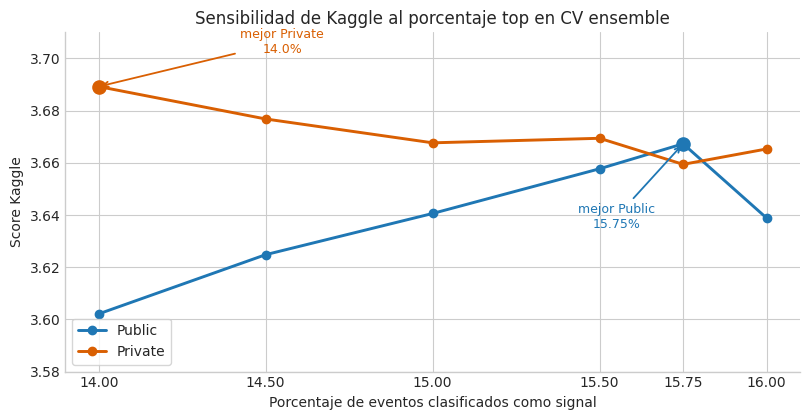

In [4]:
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(8.2, 4.3))

ax.plot(
    kaggle_results["top_signal_percent"],
    kaggle_results["public"],
    marker="o",
    linewidth=2.1,
    color="#1f77b4",
    label="Public",
)
ax.plot(
    kaggle_results["top_signal_percent"],
    kaggle_results["private"],
    marker="o",
    linewidth=2.1,
    color="#d95f02",
    label="Private",
)

best_public = kaggle_results.loc[kaggle_results["public"].idxmax()]
best_private = kaggle_results.loc[kaggle_results["private"].idxmax()]

ax.scatter([best_public["top_signal_percent"]], [best_public["public"]], s=90, color="#1f77b4", zorder=5)
ax.scatter([best_private["top_signal_percent"]], [best_private["private"]], s=90, color="#d95f02", zorder=5)

ax.annotate(
    "mejor Public\n15.75%",
    xy=(best_public["top_signal_percent"], best_public["public"]),
    xytext=(15.55, 3.635),
    arrowprops={"arrowstyle": "->", "color": "#1f77b4", "lw": 1.3},
    color="#1f77b4",
    fontsize=9,
    ha="center",
)
ax.annotate(
    "mejor Private\n14.0%",
    xy=(best_private["top_signal_percent"], best_private["private"]),
    xytext=(14.55, 3.702),
    arrowprops={"arrowstyle": "->", "color": "#d95f02", "lw": 1.3},
    color="#d95f02",
    fontsize=9,
    ha="center",
)

ax.set_xlabel("Porcentaje de eventos clasificados como signal")
ax.set_ylabel("Score Kaggle")
ax.set_title("Sensibilidad de Kaggle al porcentaje top en CV ensemble")
ax.set_xticks(kaggle_results["top_signal_percent"])
ax.set_ylim(3.58, 3.71)
ax.legend(frameon=True, loc="lower left")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.tight_layout()
fig.savefig(output_path, dpi=220, bbox_inches="tight")
output_path